# Tutor results

In [1]:
import json
import sys
from pathlib import Path

import grid2op
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from lightsim2grid import LightSimBackend
from matplotlib.cm import ScalarMappable
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.lines import Line2D

ROOT = Path("..").resolve()
sys.path.insert(0, str(ROOT / "src"))

from imitation.dataset import soft_targets
from imitation.summary import load_states, load_tutor_state
from imitation.tutor import DO_NOTHING_INDEX
from visualization.utils import GridPlottingArgs, visualize_grid

# ── Paths ──
SUMMARY = ROOT / "results/tutor/2026_10_12_imitation_case36_k208/summary"
EXPERIENCE = ROOT / "results/tutor/2026_10_12_imitation_case36_k208/experience"

# ── Constants ──
STEPS_PER_DAY = 288  # 5-minute intervals
MONTHS = ["january", "february", "march", "april", "may", "june",
          "july", "august", "september", "october", "november", "december"]
MONTH_LABELS = [m[:3].capitalize() for m in MONTHS]

# ── Palette ──
COLORS = {"complete": "#2a78d6", "never run": "#1baf7a", "truncated": "#eb6834"}
SURFACE, INK, INK_MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
CMAP = LinearSegmentedColormap.from_list(
    "seq_blue", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])


def style(ax: plt.Axes) -> None:
    ax.set_facecolor(SURFACE)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GRID)
    ax.tick_params(colors=INK_MUTED, length=0)
    ax.yaxis.grid(True, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)

/home/adrian/.conda/envs/L2RPN/lib/python3.10/site-packages/grid2op/MakeEnv/Make.py:13: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


/home/adrian/.conda/envs/L2RPN/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026-10-22 13:12:31,406	INFO util.py:154 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.


2026-10-22 13:12:34,339	INFO util.py:154 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.


In [2]:
env = grid2op.make("l2rpn_wcci_2020", backend=LightSimBackend())

episodes = pd.read_csv(SUMMARY / "episodes.csv")
episodes["month"] = pd.Categorical(
    episodes["chronic"].str.split("_").str[1], categories=MONTHS, ordered=True)
episodes["days_survived"] = episodes["steps_survived"] / STEPS_PER_DAY

actions = pd.read_csv(SUMMARY / "actions.csv")
substations = pd.read_csv(SUMMARY / "substations.csv")
states = load_states(SUMMARY / "states.npz")

max_rho, valid, chosen = states["max_rho"], states["valid"], states["action"]

print(f"{len(episodes)} chronics, {episodes['survived'].mean():.1%} fully survived, "
      f"mean survival {(episodes['steps_survived'] / episodes['max_step']).mean():.1%}")
print(f"{len(chosen):,} recorded states x {max_rho.shape[1]} actions, {env.n_sub} substations")

2592 chronics, 76.6% fully survived, mean survival 87.0%
94,742 recorded states x 209 actions, 36 substations


# Stored data format

The Tutor summary (`imitation.summary.summarize_tutor_run`) writes four files.

## `episodes.csv` — one row per chronic

| Column | Description |
|---|---|
| `chronic` | Scenario name, e.g. `Scenario_april_000` |
| `steps_survived` | Steps before game-over (or `max_step` if survived) |
| `max_step` | Total steps in the chronic |
| `survived` | Whether the agent survived the entire chronic |
| `n_decisions` | Number of states where the Tutor actively chose an action (rho > threshold) |

In [3]:
episodes.sample(5, random_state=0)

,agent,chronic,seed,steps_survived,max_step,survived,truncated,n_decisions,month,days_survived
182,tutor,Scenario_april_203,465177046,8062,8062,True,False,12,april,27.993056
2078,tutor,Scenario_november_158,500968132,8062,8062,True,False,38,november,27.993056
1012,tutor,Scenario_january_173,181032744,8062,8062,True,False,78,january,27.993056
1922,tutor,Scenario_may_232,1084427783,8062,8062,True,False,4,may,27.993056
1833,tutor,Scenario_may_136,1166571463,8062,8062,True,False,20,may,27.993056


## `actions.csv` — one row per action in the policy's action space

| Column | Description |
|---|---|
| `index` | Action index (0 = do-nothing) |
| `substation` | Target substation (-1 for do-nothing) |
| `n_elements` | Number of `set_bus` entries in the action |
| `teacher_rank` | Rank in the Teacher's action-space JSON (1 = most frequent Teacher action; 0 for do-nothing) |
| `tutor_picks` | Times the Tutor executed this action |
| `tutor_best` | Times this action had the lowest simulated max-rho among valid actions |
| `action` | JSON representation of the action |

In [4]:
actions.head(10)

,index,substation,n_elements,teacher_rank,tutor_picks,tutor_best,action
0,0,-1,0,0,3378,776,{}
1,1,1,6,1,0,0,"{""set_bus"": {""loads_id"": [[""load_1_2"", 1], [""l..."
2,2,19,3,2,149,155,"{""set_bus"": {""loads_id"": [[""load_19_20"", 1]], ..."
3,3,12,4,3,342,352,"{""set_bus"": {""loads_id"": [[""load_12_13"", 1]], ..."
4,4,11,3,4,758,773,"{""set_bus"": {""loads_id"": [[""load_11_12"", 1]], ..."
5,5,11,3,5,528,548,"{""set_bus"": {""loads_id"": [[""load_11_12"", 1]], ..."
6,6,4,6,6,568,572,"{""set_bus"": {""lines_or_id"": [[""4_6_5"", 1], [""4..."
7,7,35,7,7,518,528,"{""set_bus"": {""loads_id"": [[""load_35_33"", 1], [..."
8,8,4,6,8,1022,1026,"{""set_bus"": {""lines_or_id"": [[""4_6_5"", 2], [""4..."
9,9,16,17,9,724,725,"{""set_bus"": {""loads_id"": [[""load_16_17"", 2]], ..."


## `states.npz` — every recorded state (one row per Tutor decision)

| Array | Shape | Description |
|---|---|---|
| `chronic` | `[n]` | Scenario name |
| `step` | `[n]` | Time-step within the chronic |
| `rho_current` | `[n]` | Max line loading (rho) *before* acting |
| `action` | `[n]` | Index of the action the Tutor executed |
| `max_rho` | `[n, A]` | Simulated max-rho after each action (NaN = invalid) |
| `valid` | `[n, A]` | Whether each action was valid (no game-over) |

Improvement of action `a` over do-nothing: `max_rho[:, 0] - max_rho[:, a]` (positive = better).

In [5]:
print(f"{len(states['action']):,} states, {max_rho.shape[1]} actions per state")
print(f"Fields: {', '.join(k for k in states if not k.startswith('meta'))}\n")

# Show a few rows as a DataFrame for readability
i_sample = np.random.default_rng(0).choice(len(chosen), 5, replace=False)
pd.DataFrame({
    "chronic": states["chronic"][i_sample],
    "step": states["step"][i_sample],
    "rho_current": states["rho_current"][i_sample],
    "action": chosen[i_sample],
    "n_valid": valid[i_sample].sum(axis=1),
    "rho_best": np.nanmin(np.where(valid, max_rho, np.nan), axis=1)[i_sample],
    "rho_do_nothing": max_rho[i_sample, DO_NOTHING_INDEX],
}).round(3)

94,742 states, 209 actions per state
Fields: chronic, step, action, max_rho, valid, rho_current



/tmp/ipykernel_1552/3411125669.py:12: RuntimeWarning: All-NaN slice encountered
  "rho_best": np.nanmin(np.where(valid, max_rho, np.nan), axis=1)[i_sample],


,chronic,step,rho_current,action,n_valid,rho_best,rho_do_nothing
0,Scenario_january_227,1623,1.045,153,162,0.780,0.928
1,Scenario_january_058,1533,0.971,150,209,0.893,0.944
2,Scenario_december_180,3840,0.975,88,207,0.825,0.987
3,Scenario_december_210,7335,0.955,27,196,0.842,0.952
4,Scenario_november_165,2121,0.971,136,205,0.938,0.980


## `substations.csv` — one row per substation

| Column | Description |
|---|---|
| `substation` | Substation index |
| `n_actions` | Number of topology actions targeting this substation |
| `tutor_picks` | Times the Tutor picked an action at this substation |
| `tutor_pick_share` | Share of all topology picks (excluding do-nothing) |
| `tutor_best` | Times an action at this substation had the lowest max-rho |

In [6]:
substations[substations["tutor_picks"] > 0].sort_values("tutor_picks", ascending=False)

,substation,n_actions,tutor_picks,tutor_pick_share,tutor_best
16,16,47,26138,0.286086,26266
23,23,48,19016,0.208134,19282
26,26,7,8065,0.088273,8145
21,21,17,8031,0.087901,8185
33,33,10,7033,0.076978,7197
9,9,14,6206,0.067926,6376
4,4,11,4842,0.052997,5149
35,35,11,2274,0.024889,2356
7,7,8,2163,0.023675,2325
22,22,3,1424,0.015586,1501


# Soft-label entropy

For imitation pretraining the Tutor's hard labels are softened into Boltzmann targets
(`imitation.dataset.soft_targets`). The labels follow the Tutor's own decision rule:

- **Support** $S(s)$: do-nothing plus every valid action that beats it by more than the margin
  $m$ (`do_nothing_margin` = 0.005), i.e. $\rho_a < \rho_{dn} - m$. Actions that are worse than
  do-nothing, or simulate to the same max rho, get probability 0.
- **Weights**: $p(a \mid s) \propto \exp(-\tilde\rho_a / T)$ over $S(s)$, with do-nothing scored as
  $\tilde\rho_{dn} = \rho_{dn} - m$ and every other action as $\tilde\rho_a = \rho_a$.
- If no action beats do-nothing by the margin, the label is one-hot on do-nothing. If do-nothing
  is invalid, all valid actions form the support.

The argmax is therefore always the Tutor's executed action (the hard label). Do-nothing keeps
probability when the best gain $\Delta^* = \rho_{dn} - \min_a \rho_a$ is small: it gets
$e^{-(\Delta^* - m)/T}$ times the weight of the best action. The temperature `T` (in absolute rho
units) controls how the mass is shared among the actions in the support.

The **left plot** shows mean entropy of the soft labels vs temperature. The dashed line marks the
entropy of a uniform distribution over the support (upper bound).

The **right plot** shows per-state *effective number of actions* `exp(H)`: how many actions share
noticeable probability mass. A value of 1 means the label is essentially hard.

The table below the plots shows the mean probability of do-nothing depending on the best gain.

/tmp/ipykernel_1552/1592477374.py:13: RuntimeWarning: invalid value encountered in subtract
  best_gain = np.where(improving.any(axis=1), rho_dn - np.where(improving, rho, np.inf).min(axis=1), 0.0)


Hard labels: entropy 0, do-nothing share 0.036
Support size: median 44, 3.6% of states have a single action in the support


,T,mean_entropy_nats,median_effective_actions,mean_normalized_entropy,mean_p_best,mean_p_do_nothing,argmax_eq_hard_label
0,0.001,0.434,1.071,0.125,0.814,0.037,1.0
1,0.002,0.719,1.789,0.208,0.715,0.039,1.0
2,0.005,1.072,2.633,0.308,0.604,0.040,1.0
3,0.010,1.565,4.776,0.447,0.464,0.043,1.0
4,0.020,2.179,9.897,0.618,0.317,0.047,1.0
5,0.050,2.971,25.270,0.834,0.171,0.055,1.0
6,0.100,3.297,37.152,0.921,0.117,0.063,1.0


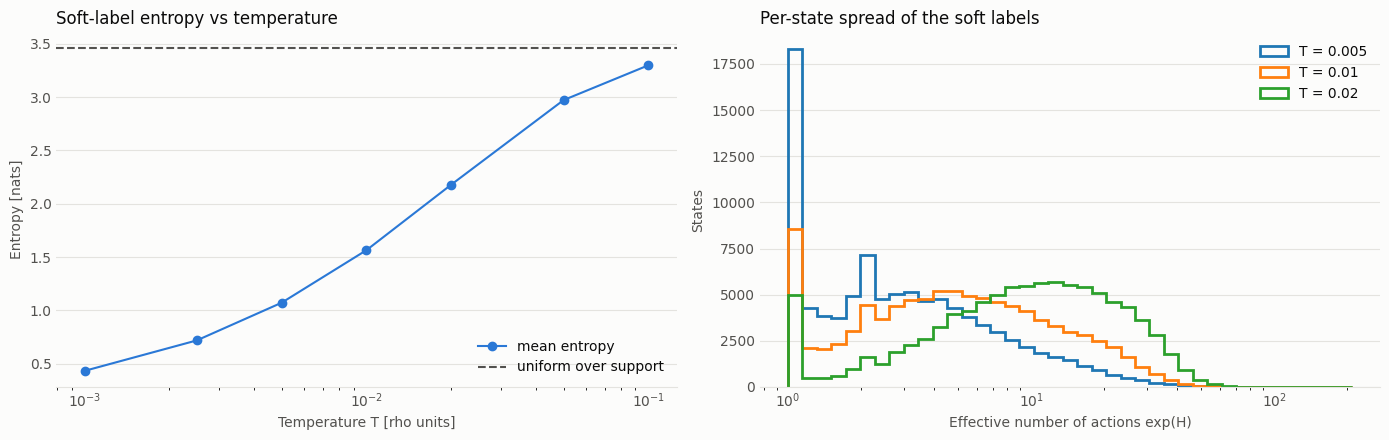

,share_of_states,p_dn_T=0.005,p_dn_T=0.01,p_dn_T=0.02
"[0.0, 0.005)",0.036,1.000,1.000,1.000
"[0.005, 0.01)",0.012,0.272,0.306,0.325
"[0.01, 0.02)",0.020,0.068,0.124,0.162
"[0.02, 0.05)",0.061,0.004,0.021,0.050
"[0.05, 0.1)",0.145,0.000,0.001,0.008
"[0.1, inf)",0.727,0.000,0.000,0.000


In [7]:
TEMPERATURES = [0.001, 0.0025, 0.005, 0.01, 0.02, 0.05, 0.1]
HIST_T = (0.005, 0.01, 0.02)
MARGIN = float(states["meta_do_nothing_margin"])

# Support of the soft labels (see markdown above); a state with an empty support targets do-nothing.
rho = np.where(valid, max_rho, np.inf)
rho_dn = rho[:, DO_NOTHING_INDEX]
support = rho < rho_dn[:, None] - MARGIN
support[:, DO_NOTHING_INDEX] = valid[:, DO_NOTHING_INDEX]
n_support = np.maximum(support.sum(axis=1), 1)
improving = support.copy()
improving[:, DO_NOTHING_INDEX] = False
best_gain = np.where(improving.any(axis=1), rho_dn - np.where(improving, rho, np.inf).min(axis=1), 0.0)


def entropy(p: np.ndarray) -> np.ndarray:
    return -(p * np.log(np.where(p > 0, p, 1.0))).sum(axis=1)


rows, per_state_h, p_dn = [], {}, {}
for t in TEMPERATURES:
    p = soft_targets(max_rho, valid, t, MARGIN)
    h = entropy(p)
    p_dn[t] = p[:, DO_NOTHING_INDEX]
    if t in HIST_T:
        per_state_h[t] = h
    rows.append({
        "T": t,
        "mean_entropy_nats": h.mean(),
        "median_effective_actions": np.median(np.exp(h)),
        "mean_normalized_entropy": np.mean(h / np.log(np.maximum(n_support, 2))),
        "mean_p_best": p.max(axis=1).mean(),
        "mean_p_do_nothing": p[:, DO_NOTHING_INDEX].mean(),
        "argmax_eq_hard_label": (p.argmax(axis=1) == chosen).mean(),
    })
entropy_df = pd.DataFrame(rows)
print(f"Hard labels: entropy 0, do-nothing share {(chosen == DO_NOTHING_INDEX).mean():.3f}")
print(f"Support size: median {np.median(n_support):.0f}, "
      f"{(n_support == 1).mean():.1%} of states have a single action in the support")
display(entropy_df.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), facecolor=SURFACE)

axes[0].plot(entropy_df["T"], entropy_df["mean_entropy_nats"],
             marker="o", color=COLORS["complete"], label="mean entropy")
axes[0].axhline(np.log(n_support).mean(),
                color=INK_MUTED, ls="--", label="uniform over support")
axes[0].set_xscale("log")
axes[0].set_xlabel("Temperature T [rho units]", color=INK_MUTED)
axes[0].set_ylabel("Entropy [nats]", color=INK_MUTED)
axes[0].set_title("Soft-label entropy vs temperature", loc="left", color=INK, fontsize=12)
axes[0].legend(frameon=False, labelcolor=INK)
style(axes[0])

bins = np.logspace(0, np.log10(max_rho.shape[1]), 40)
for t, h in per_state_h.items():
    axes[1].hist(np.exp(h), bins=bins, histtype="step", lw=2,
                 label=f"T = {t}")
axes[1].set_xscale("log")
axes[1].set_xlabel("Effective number of actions exp(H)", color=INK_MUTED)
axes[1].set_ylabel("States", color=INK_MUTED)
axes[1].set_title("Per-state spread of the soft labels", loc="left", color=INK, fontsize=12)
axes[1].legend(frameon=False, labelcolor=INK)
style(axes[1])

fig.tight_layout()
plt.show()

# Mean p(do-nothing) by best gain over do-nothing
gain_bins = [0, MARGIN, 0.01, 0.02, 0.05, 0.1, np.inf]
gain_group = pd.cut(pd.Series(best_gain), gain_bins, right=False)
display(pd.DataFrame({"share_of_states": gain_group.value_counts(normalize=True, sort=False),
                      **{f"p_dn_T={t}": pd.Series(p_dn[t]).groupby(gain_group, observed=False).mean()
                         for t in HIST_T}}).round(3))

# Survival duration per month

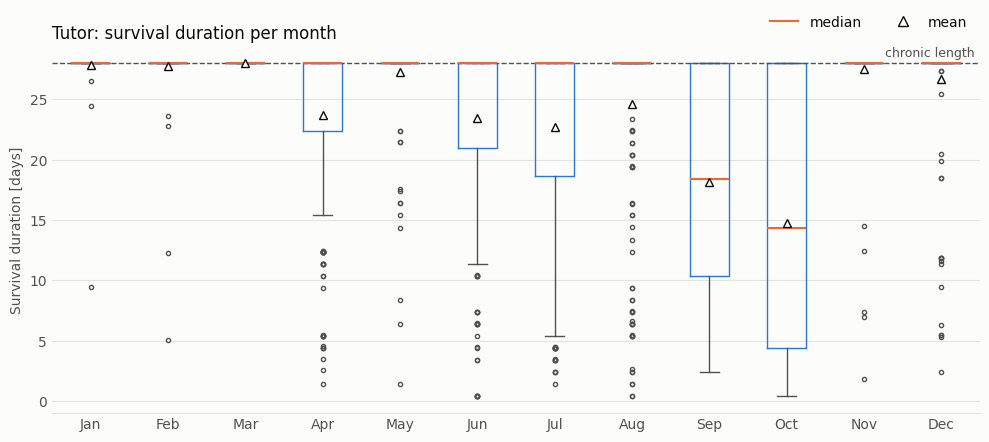

In [8]:
fig, ax = plt.subplots(figsize=(10, 4.5), facecolor=SURFACE)
data = [episodes.loc[episodes["month"] == m, "days_survived"] for m in MONTHS]
ax.boxplot(data, tick_labels=MONTH_LABELS, showmeans=True,
           boxprops=dict(color=COLORS["complete"]),
           whiskerprops=dict(color=INK_MUTED),
           capprops=dict(color=INK_MUTED),
           medianprops=dict(color=COLORS["truncated"], linewidth=1.5),
           flierprops=dict(marker="o", markeredgecolor=INK_MUTED, markersize=3),
           meanprops=dict(marker="^", markerfacecolor="white", markeredgecolor=INK))

chronic_days = episodes["max_step"].max() / STEPS_PER_DAY
ax.axhline(chronic_days, color=INK_MUTED, ls="--", lw=1)
ax.annotate("chronic length",
            xy=(1, chronic_days), xycoords=("axes fraction", "data"),
            xytext=(-4, 3), textcoords="offset points",
            ha="right", va="bottom", color=INK_MUTED, fontsize=9)

legend_handles = [
    Line2D([0], [0], color=COLORS["truncated"], linewidth=1.5, label="median"),
    Line2D([0], [0], marker="^", color="none", markerfacecolor="white",
           markeredgecolor=INK, markersize=7, label="mean"),
]
ax.legend(handles=legend_handles, frameon=False, ncols=2,
          loc="upper right", bbox_to_anchor=(1, 1.12), labelcolor=INK)
ax.set_ylabel("Survival duration [days]", color=INK_MUTED)
ax.set_title("Tutor: survival duration per month", loc="left", color=INK, fontsize=12)
style(ax)
fig.tight_layout()
plt.show()

# Survival ratio per month

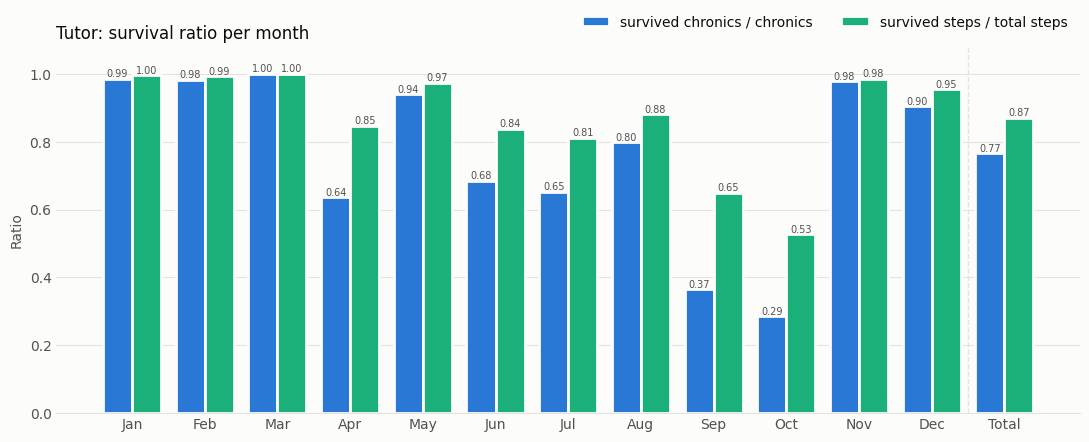

,chronics,survived_chronics,steps_survived,steps_total,chronic_ratio,step_ratio
january,215.0,212.0,1726575.0,1733330.0,0.986047,0.996103
february,216.0,212.0,1727514.0,1741392.0,0.981481,0.992031
march,215.0,215.0,1733330.0,1733330.0,1.000000,1.000000
april,214.0,136.0,1461796.0,1725268.0,0.635514,0.847286
may,214.0,201.0,1678502.0,1725268.0,0.939252,0.972893
june,219.0,150.0,1480126.0,1765578.0,0.684932,0.838324
july,210.0,137.0,1374323.0,1693020.0,0.652381,0.811758
august,218.0,174.0,1547940.0,1757516.0,0.798165,0.880754
september,219.0,80.0,1146124.0,1765578.0,0.365297,0.649149
october,221.0,63.0,938694.0,1781702.0,0.285068,0.526852


In [9]:
per_month = episodes.groupby("month", observed=False).agg(
    chronics=("chronic", "size"),
    survived_chronics=("survived", "sum"),
    steps_survived=("steps_survived", "sum"),
    steps_total=("max_step", "sum"),
)
per_month["chronic_ratio"] = per_month["survived_chronics"] / per_month["chronics"]
per_month["step_ratio"] = per_month["steps_survived"] / per_month["steps_total"]

# Add a "Total" row
total = per_month.sum(numeric_only=True)
total["chronic_ratio"] = total["survived_chronics"] / total["chronics"]
total["step_ratio"] = total["steps_survived"] / total["steps_total"]
per_month_with_total = pd.concat([per_month, pd.DataFrame(total).T.rename({0: "Total"})])

labels = MONTH_LABELS + ["Total"]
x = range(len(labels))
width = 0.4
fig, ax = plt.subplots(figsize=(11, 4.5), facecolor=SURFACE)

c_vals = per_month_with_total["chronic_ratio"]
s_vals = per_month_with_total["step_ratio"]
bars_c = ax.bar([i - width / 2 for i in x], c_vals, width,
                label="survived chronics / chronics",
                color=COLORS["complete"], edgecolor=SURFACE, linewidth=2)
bars_s = ax.bar([i + width / 2 for i in x], s_vals, width,
                label="survived steps / total steps",
                color=COLORS["never run"], edgecolor=SURFACE, linewidth=2)
ax.bar_label(bars_c, fmt="%.2f", fontsize=7, color=INK_MUTED)
ax.bar_label(bars_s, fmt="%.2f", fontsize=7, color=INK_MUTED)

# Separator line before the Total column
ax.axvline(x=len(MONTH_LABELS) - 0.5, color=GRID, linewidth=1, linestyle="--")

ax.set_xticks(list(x), labels)
ax.set_ylim(0, 1.08)
ax.set_ylabel("Ratio", color=INK_MUTED)
ax.set_title("Tutor: survival ratio per month", loc="left", color=INK, fontsize=12)
ax.legend(frameon=False, ncols=2, loc="upper right", bbox_to_anchor=(1, 1.12), labelcolor=INK)
style(ax)
fig.tight_layout()
plt.show()

per_month_with_total

# Dataset coverage

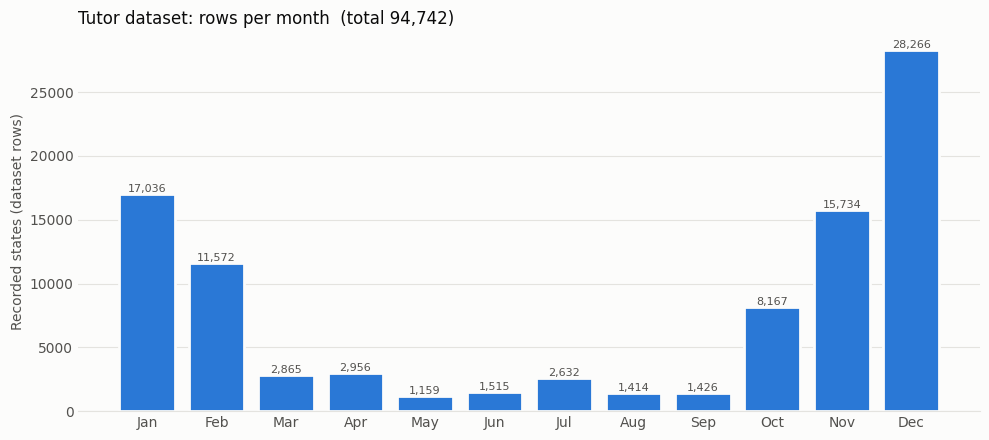

In [10]:
rows_per_month = episodes.groupby("month", observed=False)["n_decisions"].sum()

fig, ax = plt.subplots(figsize=(10, 4.5), facecolor=SURFACE)
bars = ax.bar(MONTH_LABELS, rows_per_month.values,
              color=COLORS["complete"], edgecolor=SURFACE, linewidth=2)
ax.bar_label(bars, labels=[f"{v:,}" for v in rows_per_month.values],
             fontsize=8, color=INK_MUTED)
ax.set_ylabel("Recorded states (dataset rows)", color=INK_MUTED)
ax.set_title(f"Tutor dataset: rows per month  (total {rows_per_month.sum():,})",
             loc="left", color=INK, fontsize=12)
style(ax)
fig.tight_layout()
plt.show()

# Substation action distribution

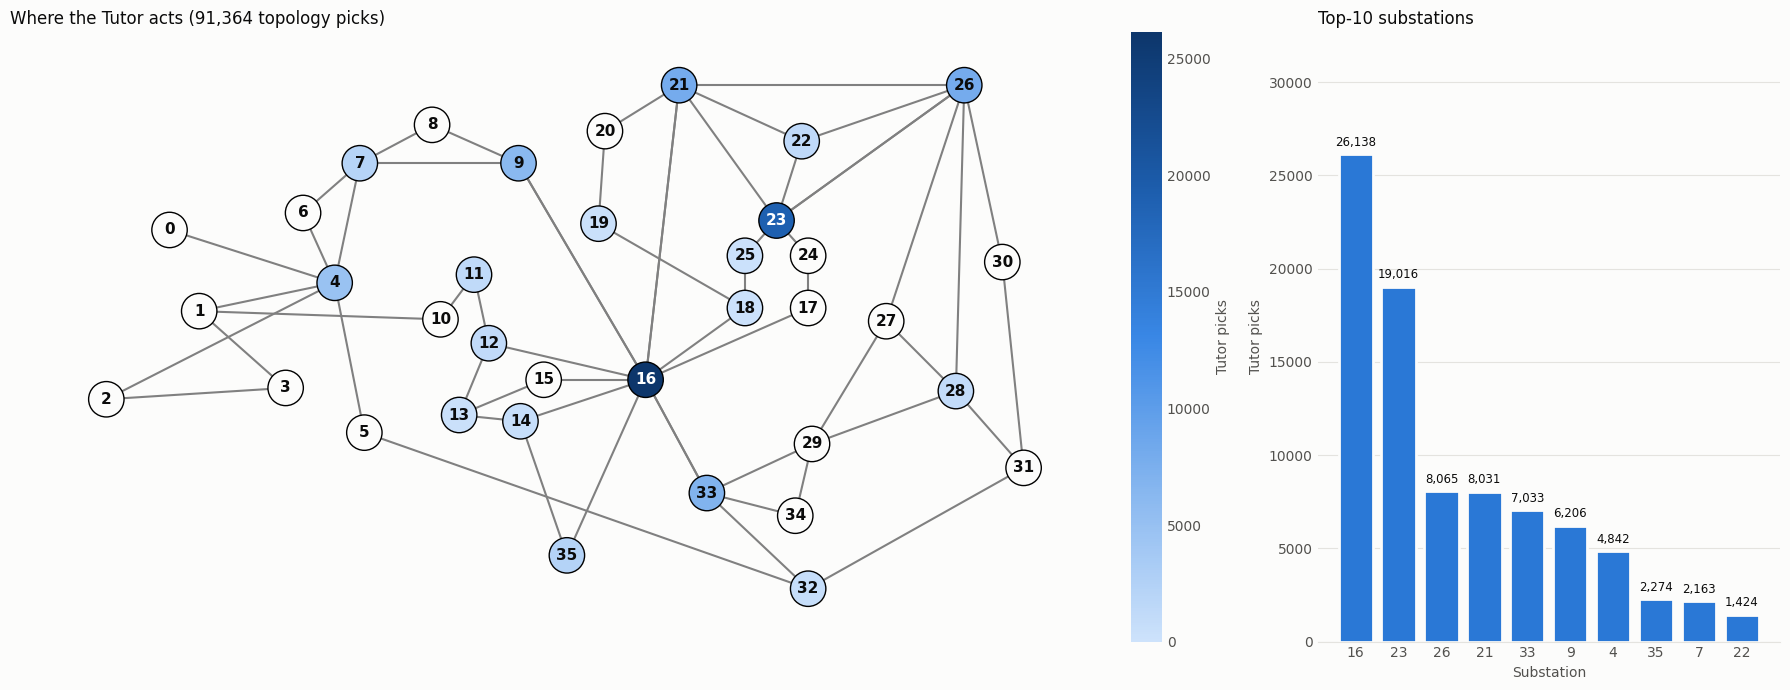

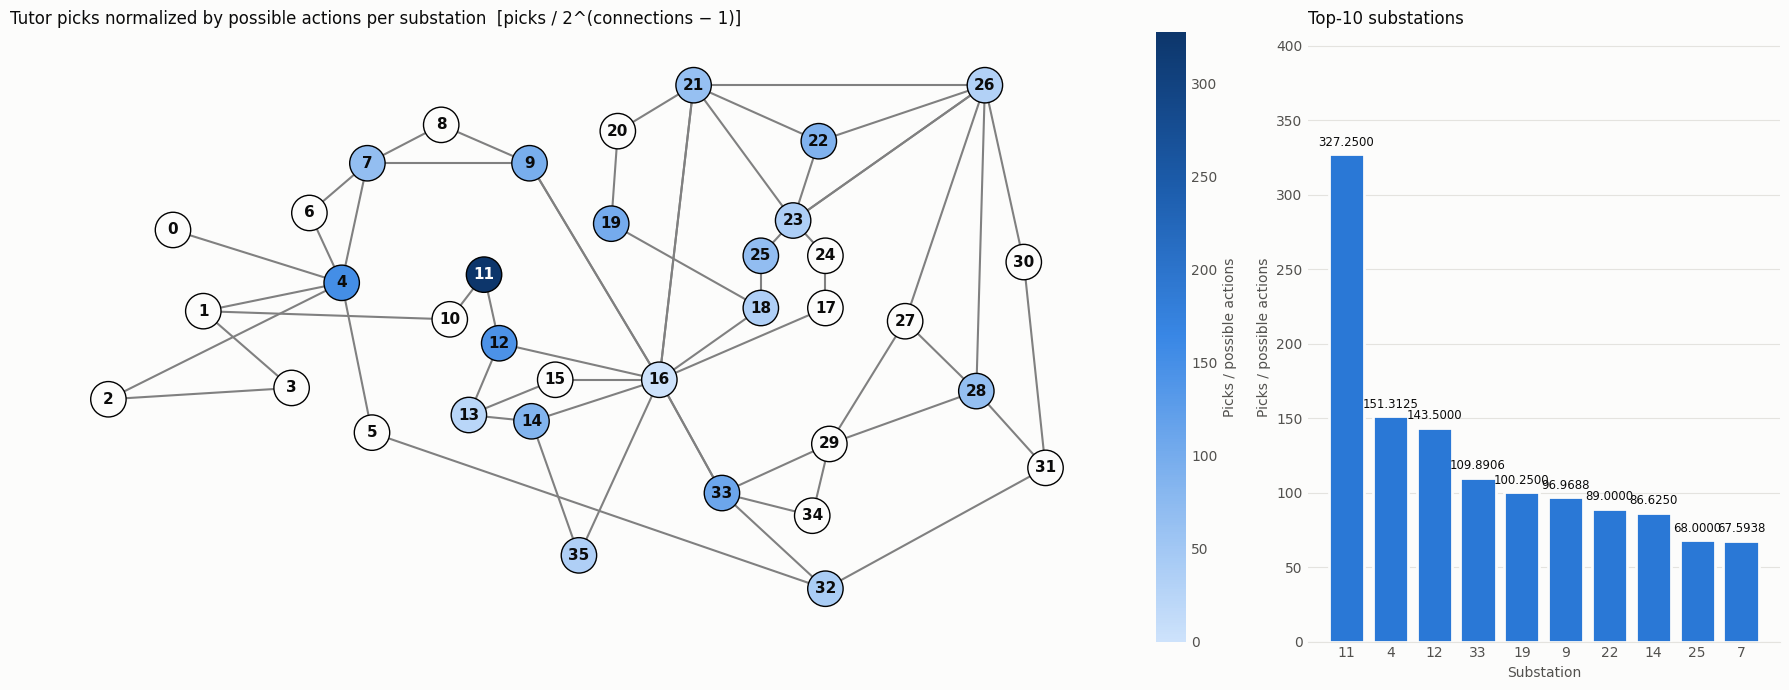

In [11]:
# Tutor topology picks per substation (excluding do-nothing)
topo_to_sub = np.repeat(np.arange(env.n_sub), env.sub_info)
possible_actions = pd.Series(2.0 ** (env.sub_info - 1), index=range(env.n_sub))
picks = substations.set_index("substation")["tutor_picks"].reindex(
    range(env.n_sub), fill_value=0)

NO_PICKS = SURFACE


def _text_ink(r: float, g: float, b: float) -> str:
    return "white" if 0.2126 * r + 0.7152 * g + 0.0722 * b < 0.5 else INK


def draw_substation_panels(values: pd.Series, title: str,
                           ylabel: str, bar_label_fmt: str) -> None:
    top10 = values.sort_values(ascending=False).head(10)
    norm = Normalize(vmin=0, vmax=values.max())
    node_colors = [CMAP(norm(values[i])) if picks[i] > 0 else NO_PICKS
                   for i in range(env.n_sub)]

    fig, (ax_grid, ax_bar) = plt.subplots(
        1, 2, figsize=(18, 7),
        gridspec_kw={"width_ratios": [2.5, 1]}, facecolor=SURFACE)

    visualize_grid(GridPlottingArgs(
        env=env, node_colors=node_colors, node_size=650, font_size=11), ax=ax_grid)
    ax_grid.set_facecolor(SURFACE)
    fig.patch.set_facecolor(SURFACE)

    for text in ax_grid.texts:
        if text.get_text().isdigit():
            sub_id = int(text.get_text())
            r, g, b, _ = (CMAP(norm(values[sub_id])) if picks[sub_id] > 0
                           else (*[c / 255 for c in (0xfc, 0xfc, 0xfb)], 1))
            text.set_color(_text_ink(r, g, b))

    sm = plt.cm.ScalarMappable(norm=norm, cmap=CMAP)
    cbar = fig.colorbar(sm, ax=ax_grid, fraction=0.03, pad=0.01)
    cbar.set_label(ylabel, color=INK_MUTED)
    cbar.outline.set_visible(False)
    cbar.ax.tick_params(colors=INK_MUTED, length=0)
    ax_grid.set_title(title, loc="left", color=INK, fontsize=12)

    bars = ax_bar.bar([str(s) for s in top10.index], top10.values,
                      color=COLORS["complete"], edgecolor=SURFACE, linewidth=2)
    for bar, (sub_id, val) in zip(bars, top10.items()):
        ax_bar.annotate(bar_label_fmt.format(val=val),
                        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                        xytext=(0, 4), textcoords="offset points",
                        ha="center", va="bottom", color=INK, fontsize=8.5)
    ax_bar.set_title("Top-10 substations", loc="left", color=INK, fontsize=12)
    ax_bar.set_xlabel("Substation", color=INK_MUTED)
    ax_bar.set_ylabel(ylabel, color=INK_MUTED)
    ax_bar.set_ylim(0, top10.max() * 1.25)
    style(ax_bar)

    plt.tight_layout()
    plt.show()


# Raw action counts
draw_substation_panels(
    picks.astype(float),
    title=f"Where the Tutor acts ({picks.sum():,} topology picks)",
    ylabel="Tutor picks",
    bar_label_fmt="{val:,.0f}",
)

# Normalized: picks / 2^(connections − 1)
draw_substation_panels(
    picks / possible_actions,
    title="Tutor picks normalized by possible actions per substation  "
          "[picks / 2^(connections − 1)]",
    ylabel="Picks / possible actions",
    bar_label_fmt="{val:.4f}",
)